# ALIFRLeaky sanity tests

Checks, in order:
1. **Regression**: with `a = b = 0` the ALIF neuron must reproduce plain `snn.RLeaky` exactly.
2. **Behaviour**: plots of membrane potential, spikes and adaptation `W` for spike-triggered (`b`) and subthreshold (`a`) adaptation, including decay after the input switches off.
3. **Gradients**: `beta_w`, `a`, `b` receive gradients.
4. **Heterogeneity**: per-neuron `beta_w` / `b` tensors.

Replace the import in the next cell with the module that defines your `ALIFRLeaky`.

In [1]:
import numpy as np
import torch
import snntorch as snn
from snntorch import surrogate
import matplotlib.pyplot as plt

from thesis_code.network_components.alif_neurons import ALIFRLeaky

torch.manual_seed(0)

In [4]:
T = 300          # time steps
BETA = 0.9       # membrane decay (tau_m = 10 steps)
THR = 1.0        # firing threshold


def make_input(T, on=20, off=200, amp=0.3, n=1):
    """Step input, shape [time, batch=1, features=n]. Input is off after `off` so adaptation can decay."""
    I = torch.zeros(T, 1, n)
    I[on:off] = amp
    return I


def zero_recurrent(neuron):
    """Switch the recurrent connection off so only the adaptation is being tested."""
    for p in neuron.recurrent.parameters():
        p.data.zero_()
    return neuron


def make_plain(n=1):
    return zero_recurrent(
        snn.RLeaky(beta=BETA, linear_features=n, all_to_all=True,
                   threshold=THR, init_hidden=False)
    )


def make_alif(n=1, beta_w=0.98, a=0.0, b=0.0, **kw):
    return zero_recurrent(
        ALIFRLeaky(beta=BETA, linear_features=n, all_to_all=True,
                   threshold=THR, beta_w=beta_w, a=a, b=b, **kw)
    )


def np_(x):
    return x.detach().cpu().numpy()


def simulate(neuron, I, grad=False):
    """Run the neuron over I [T, batch, n]. Returns dict of tensors [T, n] (batch element 0)."""
    is_alif = isinstance(neuron, ALIFRLeaky)
    mems, spks, adpts = [], [], []
    with torch.set_grad_enabled(grad):
        if is_alif:
            spk, mem, adpt = neuron.init_rleaky()
            adpt = torch.zeros_like(I[0])  # explicit zero state (see note at the end)
            for t in range(I.shape[0]):
                spk, mem, adpt = neuron(I[t], spk, mem, adpt)
                adpts.append(adpt[0].clone())
                mems.append(mem[0].clone())
                spks.append(spk[0].clone())
        else:
            spk, mem = neuron.init_rleaky()
            for t in range(I.shape[0]):
                spk, mem = neuron(I[t], spk, mem)
                mems.append(mem[0].clone())
                spks.append(spk[0].clone())

    out = {'mem': torch.stack(mems), 'spk': torch.stack(spks)}
    out['adpt'] = torch.stack(adpts) if is_alif else torch.zeros_like(out['mem'])
    return out

## 1. Regression test: `a = b = 0` must equal plain `RLeaky`

In [5]:
I = make_input(T)

plain = make_plain()
alif0 = make_alif(a=0.0, b=0.0)

r_plain = simulate(plain, I)
r_alif0 = simulate(alif0, I)

n_spikes = int(r_plain['spk'].sum().item())
assert n_spikes > 0, 'plain RLeaky never spiked, increase the input amplitude'
assert torch.allclose(r_plain['mem'], r_alif0['mem'], atol=1e-6), 'membrane traces differ'
assert torch.equal(r_plain['spk'], r_alif0['spk']), 'spike trains differ'
print('OK: ALIF with a=b=0 reproduces plain RLeaky (' + str(n_spikes) + ' spikes)')

OK: ALIF with a=b=0 reproduces plain RLeaky (41 spikes)


## 2. Adaptation behaviour

- plain `RLeaky`: reference
- **b only**: spike-triggered adaptation (each spike raises `W`, firing rate should drop over time)
- **a only**: subthreshold adaptation (`W` follows `a * U`)
- **a + b**: both

The input switches off at t = 200, so `W` should decay back towards 0 with time constant `1 / (1 - beta_w)`.

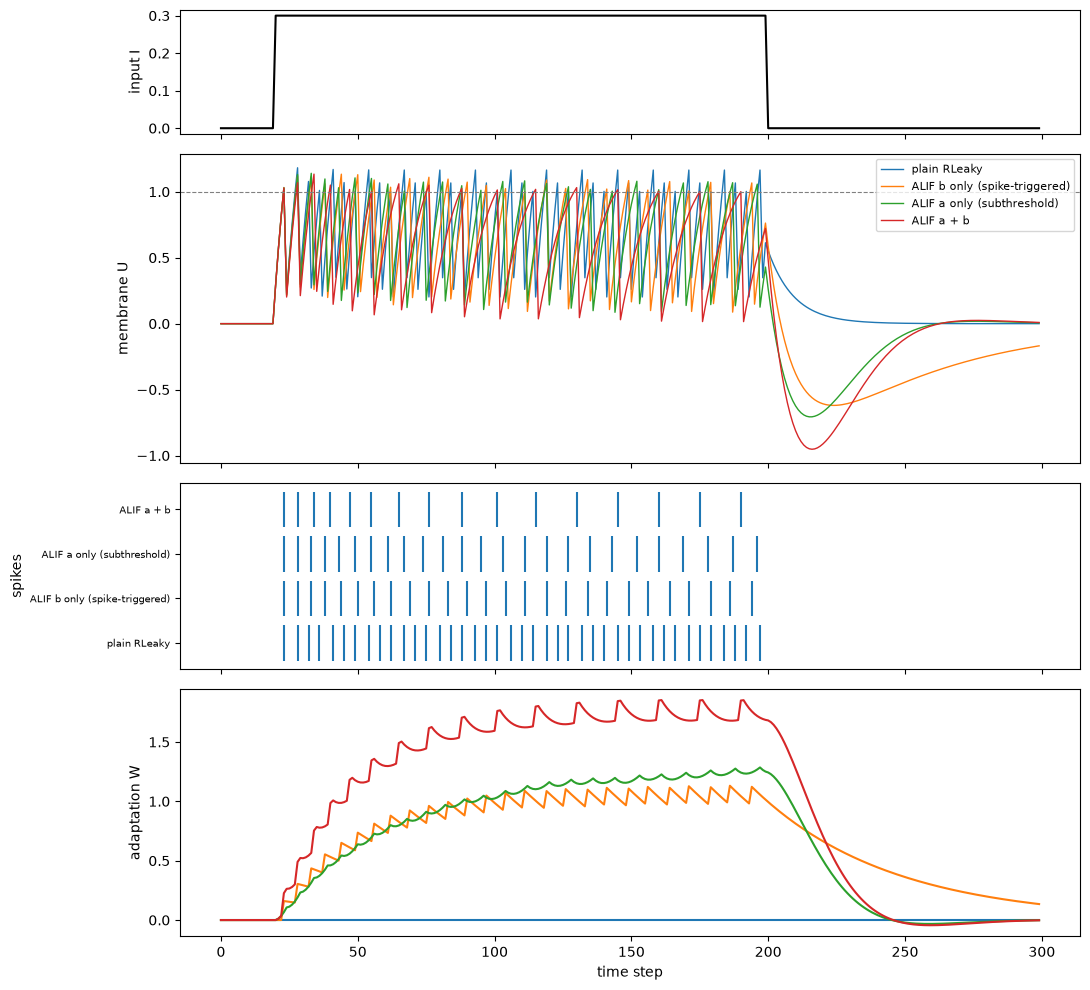

In [6]:
configs = {
    'plain RLeaky': make_plain(),
    'ALIF b only (spike-triggered)': make_alif(a=0.0, b=8.0),
    'ALIF a only (subthreshold)': make_alif(a=2.0, b=0.0),
    'ALIF a + b': make_alif(a=2.0, b=8.0),
}
results = {name: simulate(neuron, I) for name, neuron in configs.items()}


def plot_results(results, I, thr=THR):
    names = list(results)
    t = np.arange(I.shape[0])
    fig, axes = plt.subplots(
        4, 1, figsize=(11, 10), sharex=True,
        gridspec_kw={'height_ratios': [1, 2.5, 1.5, 2]},
    )

    axes[0].plot(t, np_(I[:, 0, 0]), color='k')
    axes[0].set_ylabel('input I')

    for name in names:
        axes[1].plot(t, np_(results[name]['mem'][:, 0]), label=name, lw=1)
        axes[3].plot(t, np_(results[name]['adpt'][:, 0]), label=name, lw=1.5)
    axes[1].axhline(thr, ls='--', color='gray', lw=0.8)
    axes[1].set_ylabel('membrane U')
    axes[1].legend(fontsize=8, loc='upper right')

    for i, name in enumerate(names):
        spike_times = np.nonzero(np_(results[name]['spk'][:, 0]))[0]
        axes[2].vlines(spike_times, i - 0.4, i + 0.4)
    axes[2].set_yticks(range(len(names)))
    axes[2].set_yticklabels(names, fontsize=7)
    axes[2].set_ylabel('spikes')

    axes[3].set_ylabel('adaptation W')
    axes[3].set_xlabel('time step')
    plt.tight_layout()
    plt.show()


plot_results(results, I)

### Numeric checks (firing rate early vs late, adaptation decay)

In [7]:
def rate(spk, lo, hi):
    return spk[lo:hi, 0].float().mean().item()


for name, r in results.items():
    early = rate(r['spk'], 20, 70)
    late = rate(r['spk'], 150, 200)
    print(f'{name:32s} early rate {early:.3f}   late rate {late:.3f}')

r = results['ALIF b only (spike-triggered)']
early = rate(r['spk'], 20, 70)
late = rate(r['spk'], 150, 200)
assert late < early, 'b > 0 should reduce the firing rate over time (check the sign of b*S)'
assert r['adpt'].max() > 0, 'adaptation never became positive'
assert r['adpt'][-1, 0] < r['adpt'][199, 0], 'adaptation should decay after the input switches off'
print('OK: spike-triggered adaptation lowers the rate and decays after input off')

plain RLeaky                     early rate 0.220   late rate 0.220
ALIF b only (spike-triggered)    early rate 0.180   late rate 0.120
ALIF a only (subthreshold)       early rate 0.180   late rate 0.120
ALIF a + b                       early rate 0.140   late rate 0.060
OK: spike-triggered adaptation lowers the rate and decays after input off


## 3. Gradient check

A surrogate gradient is passed explicitly so that `b` (which acts through the spike `S`) can receive gradient.

In [8]:
neuron = make_alif(a=0.5, b=2.0, beta_w=0.9, spike_grad=surrogate.fast_sigmoid(slope=25))
out = simulate(neuron, I[:100], grad=True)
loss = out['mem'].pow(2).mean() + out['spk'].mean()
loss.backward()

for pname in ['beta_w', 'a', 'b']:
    p = getattr(neuron, pname)
    print(f'{pname:7s} value {p.item():.4f}   grad {p.grad}')
    assert p.grad is not None, pname + ' got no gradient'
print('OK: beta_w, a and b all receive gradients')

beta_w  value 0.9000   grad 0.5450559854507446
a       value 0.5000   grad -0.3927522897720337
b       value 2.0000   grad -0.10142117738723755
OK: beta_w, a and b all receive gradients


## 4. Per-neuron parameters

Three neurons with different adaptation time constants and spike-triggered strengths (tensors of shape `[n]`).

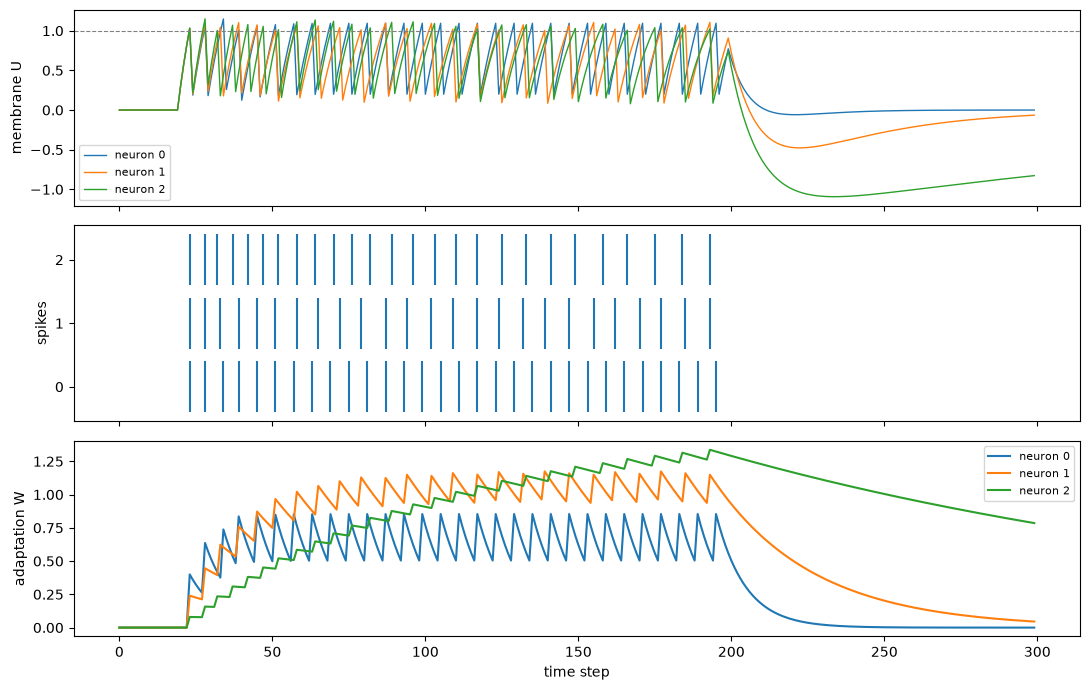

In [9]:
n = 3
het = make_alif(
    n=n,
    beta_w=torch.tensor([0.90, 0.97, 0.995]),
    a=torch.zeros(n),
    b=torch.tensor([4.0, 8.0, 16.0]),
)
I3 = make_input(T, n=n)
r3 = simulate(het, I3)

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
t = np.arange(T)
for j in range(n):
    axes[0].plot(t, np_(r3['mem'][:, j]), lw=1, label='neuron ' + str(j))
    axes[1].vlines(np.nonzero(np_(r3['spk'][:, j]))[0], j - 0.4, j + 0.4)
    axes[2].plot(t, np_(r3['adpt'][:, j]), lw=1.5, label='neuron ' + str(j))
axes[0].axhline(THR, ls='--', color='gray', lw=0.8)
axes[0].set_ylabel('membrane U')
axes[0].legend(fontsize=8)
axes[1].set_yticks(range(n))
axes[1].set_ylabel('spikes')
axes[2].set_ylabel('adaptation W')
axes[2].set_xlabel('time step')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Notes

- `simulate` passes an explicit zero `adpt` at the start. If you call `ALIFRLeaky.forward(...)` with `adpt=None` and the shape matches the previous call, it **reuses the old `self.adpt`**, so adaptation leaks from one sequence into the next. Call `reset_mem()` or pass zeros between sequences.
- If the regression test fails on the very first step, check how your snnTorch version handles `spk=None` / `mem=None` defaults in `RLeaky.forward`; this script avoids that by passing the states from `init_rleaky()` explicitly.